<a href="https://colab.research.google.com/github/Aasta-EB/Group05-_KaggleCompetition/blob/I%C5%9F%C4%B1lay-Branch/MLgroup05!.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# We import the libraries that we need for our project.
# Re and Unicodedata help us prepare multilingual text.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata

# This makes tables easier to read in Google Colab.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# We load the three official data files.
# train.csv contains examples with their correct labels.
# test.csv contains examples for which we must predict labels.
# sample_submission.csv shows the format required by Kaggle.

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
sample_submission = pd.read_csv("/content/sample_submission.csv")

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [ ]:
# We check how many rows and columns each dataset contains.
# We also display the first five rows to understand the data.

print("Training dataset:")
print("Shape:", train.shape)
display(train.head())

print("Test dataset:")
print("Shape:", test.shape)
display(test.head())

print("Sample submission:")
display(sample_submission.head())

# We check the column names to understand what information is available.
print("Column names:", train.columns.tolist())

Training dataset:
Shape: (12120, 6)


,id,premise,hypothesis,lang_abv,language,label
0,5130fd2cb5,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,en,English,0
1,5b72532a0b,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,en,English,2
2,3931fbe82a,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,J'essayais d'accomplir quelque chose.,fr,French,0
3,5622f0c60b,you know they can't really defend themselves like somebody grown uh say my age you know yeah,They can't defend themselves because of their age.,en,English,0
4,86aaa48b45,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสดงออกและได้เล่นหลายบทบาทไปพร้อมกัน ๆ อาจช่วยให้เด็กจับความคล้ายคลึงและความแตกต่างระหว่างผู้คนในด้านคว...,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,th,Thai,1


Test dataset:
Shape: (5195, 5)


,id,premise,hypothesis,lang_abv,language
0,c6d58c3f69,بکس، کیسی، راہیل، یسعیاہ، کیلی، کیلی، اور کولمبین ہائی اسکول کے دوسرے طلبا کے نام سے بکسوں کو نشان زد کیا جائے گا جس نے اس سال پہلے اپنی زندگی کھو دی,"کیسی کے لئے کوئی یادگار نہیں ہوگا, کولمین ہائی اسکول کے طالب علموں میں سے ایک جو مر گیا.",ur,Urdu
1,cefcc82292,هذا هو ما تم نصحنا به.,عندما يتم إخبارهم بما يجب عليهم فعله ، فشلت الإدارة في السماح لنا بالدخول إلى الأسرار التجارية.,ar,Arabic
2,e98005252c,et cela est en grande partie dû au fait que les mères prennent de la drogue,Les mères se droguent.,fr,French
3,58518c10ba,与城市及其他公民及社区组织代表就IMA的艺术发展进行对话&amp,IMA与其他组织合作，因为它们都依靠共享资金。,zh,Chinese
4,c32b0d16df,Она все еще была там.,"Мы думали, что она ушла, однако, она осталась.",ru,Russian


Sample submission:


,id,prediction
0,c6d58c3f69,1
1,cefcc82292,1
2,e98005252c,1
3,58518c10ba,1
4,c32b0d16df,1


Column names: ['id', 'premise', 'hypothesis', 'lang_abv', 'language', 'label']


In [ ]:
# We check the type of each column and how many values are available.
# This helps us identify missing information and understand our data.

print("Training dataset information:")
train.info()

print("\nTest dataset information:")
test.info()

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12120 entries, 0 to 12119
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          12120 non-null  object
 1   premise     12120 non-null  object
 2   hypothesis  12120 non-null  object
 3   lang_abv    12120 non-null  object
 4   language    12120 non-null  object
 5   label       12120 non-null  int64 
dtypes: int64(1), object(5)
memory usage: 568.3+ KB

Test dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5195 entries, 0 to 5194
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          5195 non-null   object
 1   premise     5195 non-null   object
 2   hypothesis  5195 non-null   object
 3   lang_abv    5195 non-null   object
 4   language    5195 non-null   object
dtypes: object(5)
memory usage: 203.1+ KB


Number of examples in each class:
label
0    4176
1    3880
2    4064
Name: count, dtype: int64


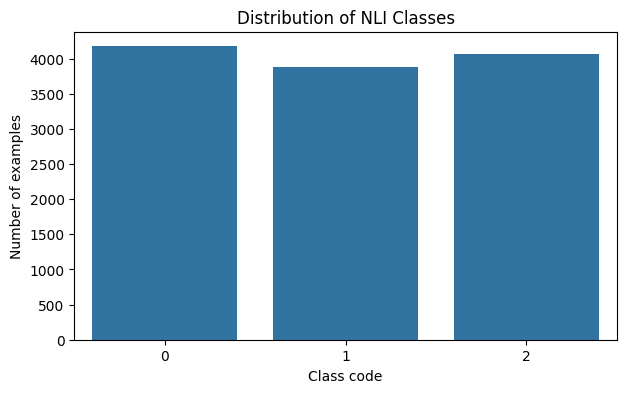

In [ ]:
# We count how many examples belong to each classification class.
# Our task has three classes: entailment, neutral and contradiction.
# This helps us understand whether the classes are balanced.

print("Number of examples in each class:")
print(train["label"].value_counts().sort_index())

# We create a graph to visualize the class distribution.
plt.figure(figsize=(7, 4))
sns.countplot(data=train, x="label")

plt.title("Distribution of NLI Classes")
plt.xlabel("Class code")
plt.ylabel("Number of examples")
plt.show()

Number of examples in each language:
language
English       6870
Chinese        411
Arabic         401
French         390
Swahili        385
Urdu           381
Vietnamese     379
Russian        376
Hindi          374
Greek          372
Thai           371
Spanish        366
Turkish        351
German         351
Bulgarian      342
Name: count, dtype: int64


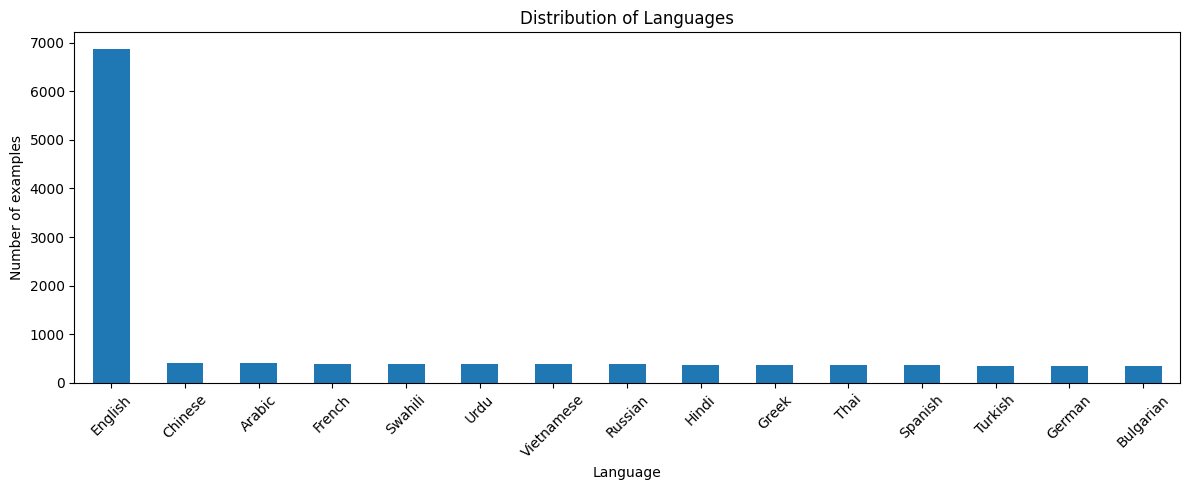

In [ ]:
# We check how many examples are available for each language.
# This is important because our project is multilingual.
# Some languages might have more examples than others.

language_column = "language" if "language" in train.columns else "lang_abv"

print("Number of examples in each language:")
print(train[language_column].value_counts())

# We create a graph to visualize the language distribution.
plt.figure(figsize=(12, 5))
train[language_column].value_counts().plot(kind="bar")

plt.title("Distribution of Languages")
plt.xlabel("Language")
plt.ylabel("Number of examples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Missing values are empty cells in our dataset.
# We check whether any premises, hypotheses or other columns
# contain missing information.

print("Missing values in training data:")
print(train.isnull().sum())

print("\nMissing values in test data:")
print(test.isnull().sum())

Missing values in training data:
id            0
premise       0
hypothesis    0
lang_abv      0
language      0
label         0
dtype: int64

Missing values in test data:
id            0
premise       0
hypothesis    0
lang_abv      0
language      0
dtype: int64


In [ ]:
# We check whether some complete rows appear more than once.
# We also check whether premises or hypotheses are repeated.
#
# A repeated premise is not necessarily a mistake.
# The same premise can have different hypotheses and labels.
# We look at these examples before deciding what to do.

print("Exact duplicate rows:", train.duplicated().sum())

print("Repeated premises:", train["premise"].duplicated().sum())

print("Repeated hypotheses:", train["hypothesis"].duplicated().sum())

# We display some examples of repeated premises.
display(
    train[train["premise"].duplicated(keep=False)]
    [["premise", "hypothesis", "label"]]
    .head(10)
)

Exact duplicate rows: 0
Repeated premises: 3911
Repeated hypotheses: 1


,premise,hypothesis,label
0,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,0
1,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,2
3,you know they can't really defend themselves like somebody grown uh say my age you know yeah,They can't defend themselves because of their age.,0
7,From Cockpit Country to St. Ann's Bay,From St. Ann's Bay to Cockpit Country.,2
8,"Look, it's your skin, but you're going to be in trouble if you don't get busy.",The boss will fire you if he sees you slacking off.,1
17,"My own little corner of the world, policy wonking, is an example.",An example is policy wonking.,0
18,life in prison then he's available for parole if it's if it's life and a day then he's not eligible for parole so what you know let's quit BSing w...,The system is corrupt because he won't be able to get parole if it's life and a day.,1
20,"North of Mytilini, stop at the village of Moria, where you will find the remains of a huge Roman aqueduct surrounded by grazing goats.",There is nothing special to see in the village of Moria.,2
21,"Increased saving by current generations would expand the nation's capital stock, allowing future generations to better afford the nation's retirem...","Current generations' increased saving would expand the nation's capital stock, allowing future generations to more easily afford the nation's reti...",0
22,"It's just the beginning!""",A great journey is about to begin!,1


In [ ]:
# We calculate how many words each premise and hypothesis contains.
# This helps us understand whether our sentences are generally
# short or long.

train["premise_length"] = (
    train["premise"].fillna("").str.split().str.len()
)

train["hypothesis_length"] = (
    train["hypothesis"].fillna("").str.split().str.len()
)

# We display basic statistics about the text lengths.
print("Premise length statistics:")
print(train["premise_length"].describe())

print("\nHypothesis length statistics:")
print(train["hypothesis_length"].describe())

Premise length statistics:
count    12120.000000
mean        17.990182
std         12.898411
min          1.000000
25%          9.000000
50%         16.000000
75%         25.000000
max        196.000000
Name: premise_length, dtype: float64

Hypothesis length statistics:
count    12120.000000
mean         9.195297
std          4.650281
min          1.000000
25%          6.000000
50%          9.000000
75%         12.000000
max         46.000000
Name: hypothesis_length, dtype: float64


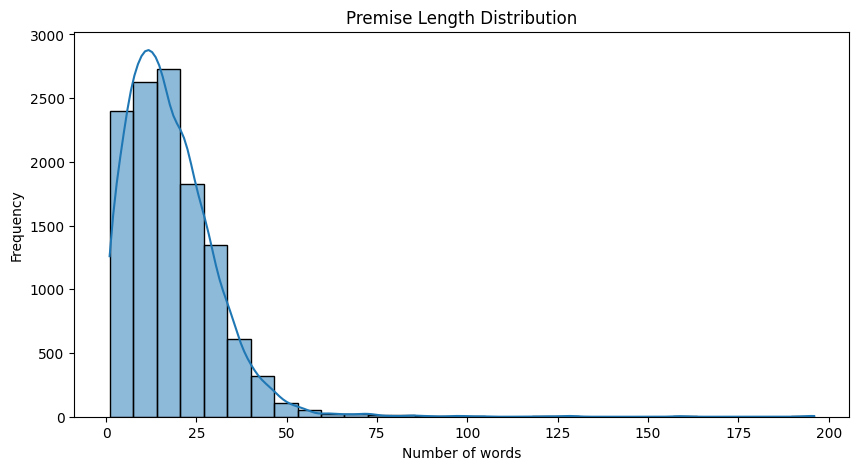

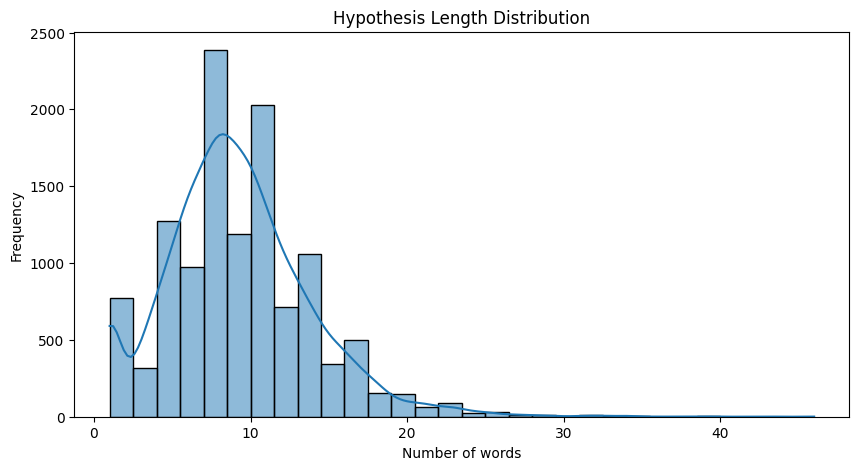

In [ ]:
# We create graphs to see how sentence lengths are distributed.
# This can help us identify unusually long or short sentences.

plt.figure(figsize=(10, 5))
sns.histplot(train["premise_length"], bins=30, kde=True)

plt.title("Premise Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()


plt.figure(figsize=(10, 5))
sns.histplot(train["hypothesis_length"], bins=30, kde=True)

plt.title("Hypothesis Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.show()

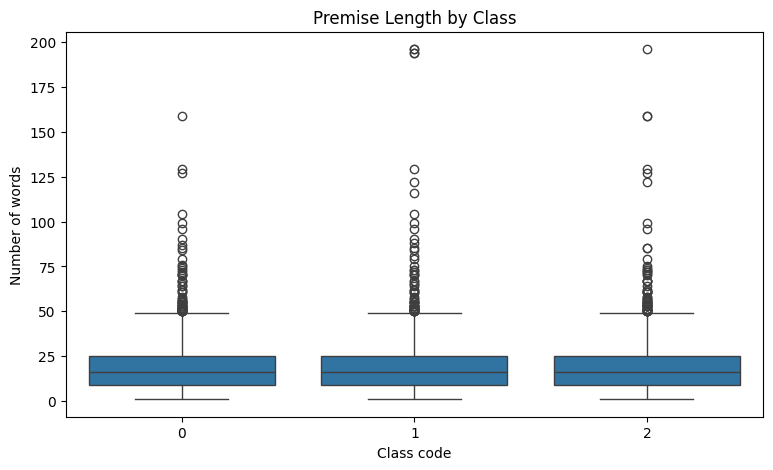

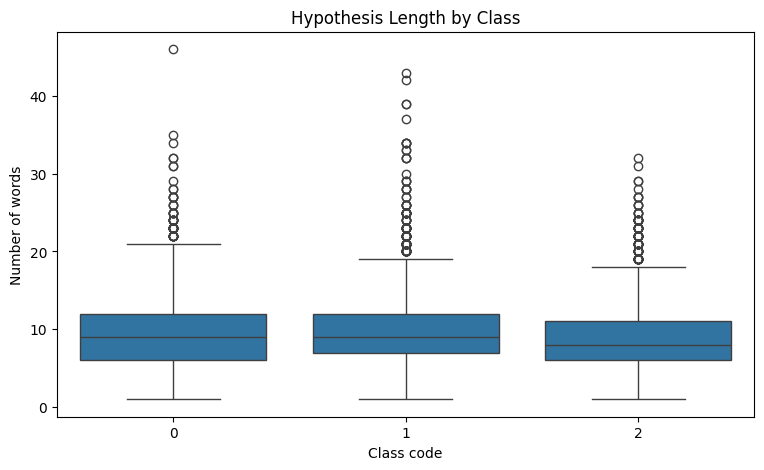

In [ ]:
# We look into whether sentence lengths differ between classes.
# This helps us explore possible relationships between text
# characteristics and the classification labels.

plt.figure(figsize=(9, 5))

sns.boxplot(data=train, x="label", y="premise_length")

plt.title("Premise Length by Class")
plt.xlabel("Class code")
plt.ylabel("Number of words")
plt.show()


plt.figure(figsize=(9, 5))

sns.boxplot(data=train, x="label", y="hypothesis_length")

plt.title("Hypothesis Length by Class")
plt.xlabel("Class code")
plt.ylabel("Number of words")
plt.show()

In [ ]:
# Before preparing the text, we check whether premises
# or hypotheses are missing.
#
# We need this information because missing text must be
# handled before using the data in a model.

print("Missing premises in training data:", train["premise"].isnull().sum())
print("Missing hypotheses in training data:", train["hypothesis"].isnull().sum())

print("Missing premises in test data:", test["premise"].isnull().sum())
print("Missing hypotheses in test data:", test["hypothesis"].isnull().sum())

Missing premises in training data: 0
Missing hypotheses in training data: 0
Missing premises in test data: 0
Missing hypotheses in test data: 0


In [ ]:
# We create a function that prepares our text.
# It handles missing values, standardizes Unicode characters
# and removes unnecessary extra spaces.
#
# We keep punctuation and negation words such as "not" and "never"
# because they can completely change the meaning of a sentence.

def preprocess_text(text):

    # If the text is missing, we temporarily replace it with an empty string.
    if pd.isna(text):
        return ""

    # We make sure that the text is in string format.
    text = str(text)

    # We standardize Unicode characters.
    text = unicodedata.normalize("NFC", text)

    # We replace multiple spaces with a single space.
    text = re.sub(r"\s+", " ", text)

    # We remove unnecessary spaces at the beginning and end.
    text = text.strip()

    return text

In [ ]:
# We apply the same preprocessing function to the training
# and test datasets.
#
# We create new columns instead of changing the original text.
# This allows us to compare the original and prepared versions.

train["premise_clean"] = train["premise"].apply(preprocess_text)
train["hypothesis_clean"] = train["hypothesis"].apply(preprocess_text)

test["premise_clean"] = test["premise"].apply(preprocess_text)
test["hypothesis_clean"] = test["hypothesis"].apply(preprocess_text)

print("Text preprocessing completed!")

Text preprocessing completed!


In [ ]:
# We combine the premise and hypothesis into one text column.
# We use clear labels to show which text is the premise
# and which text is the hypothesis.
#
# This is important because our model must understand
# the relationship between the two sentences.

train["text_pair"] = (
    "premise: " + train["premise_clean"] +
    " hypothesis: " + train["hypothesis_clean"]
)

test["text_pair"] = (
    "premise: " + test["premise_clean"] +
    " hypothesis: " + test["hypothesis_clean"]
)

print("Premise and hypothesis combined successfully!")

Premise and hypothesis combined successfully!


In [ ]:
# We display the original and prepared sentences side by side.
# This helps us check that preprocessing has not changed
# the meaning of the sentences.

display(
    train[
        [
            "premise",
            "premise_clean",
            "hypothesis",
            "hypothesis_clean",
            "text_pair"
        ]
    ].head(10)
)

,premise,premise_clean,hypothesis,hypothesis_clean,text_pair
0,and these comments were considered in formulating the interim rules.,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,The rules developed in the interim were put together with these comments in mind.,premise: and these comments were considered in formulating the interim rules. hypothesis: The rules developed in the interim were put together wit...
1,"These are issues that we wrestle with in practice groups of law firms, she said.","These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,Practice groups are not permitted to work on these issues.,"premise: These are issues that we wrestle with in practice groups of law firms, she said. hypothesis: Practice groups are not permitted to work on..."
2,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,J'essayais d'accomplir quelque chose.,J'essayais d'accomplir quelque chose.,premise: Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire. hypothesis: J'essayais d'accomplir quelque c...
3,you know they can't really defend themselves like somebody grown uh say my age you know yeah,you know they can't really defend themselves like somebody grown uh say my age you know yeah,They can't defend themselves because of their age.,They can't defend themselves because of their age.,premise: you know they can't really defend themselves like somebody grown uh say my age you know yeah hypothesis: They can't defend themselves bec...
4,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสดงออกและได้เล่นหลายบทบาทไปพร้อมกัน ๆ อาจช่วยให้เด็กจับความคล้ายคลึงและความแตกต่างระหว่างผู้คนในด้านคว...,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสดงออกและได้เล่นหลายบทบาทไปพร้อมกัน ๆ อาจช่วยให้เด็กจับความคล้ายคลึงและความแตกต่างระหว่างผู้คนในด้านคว...,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,premise: ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสดงออกและได้เล่นหลายบทบาทไปพร้อมกัน ๆ อาจช่วยให้เด็กจับความคล้ายคลึงและความแตกต่างระหว่างผู้ค...
5,"Bir çiftlikte birisinin, ağıla kapatılmış bu öküzleri kesmeliyiz dediğini duyabilirsiniz bu muhtemelen şu anlama gelir, yüklenecek olanları ayırın.","Bir çiftlikte birisinin, ağıla kapatılmış bu öküzleri kesmeliyiz dediğini duyabilirsiniz bu muhtemelen şu anlama gelir, yüklenecek olanları ayırın.",Çiftlikte insanlar farklı terimler kullanırlar.,Çiftlikte insanlar farklı terimler kullanırlar.,"premise: Bir çiftlikte birisinin, ağıla kapatılmış bu öküzleri kesmeliyiz dediğini duyabilirsiniz bu muhtemelen şu anlama gelir, yüklenecek olanla..."
6,ریاست ہائے متحدہ امریکہ واپس آنے پر، ہج ایف بی آئی کے ایجنٹوں کے ذریعے ہوائی اڈے پر ملاقات کی، تحقیقات کی، اور اگلے دن وفاقی گرین جوری سے پہلے اسا...,ریاست ہائے متحدہ امریکہ واپس آنے پر، ہج ایف بی آئی کے ایجنٹوں کے ذریعے ہوائی اڈے پر ملاقات کی، تحقیقات کی، اور اگلے دن وفاقی گرین جوری سے پہلے اسا...,ہیگ کی تفتیش ایف بی آئی اہلکاروں کی طرف سے کی گئی,ہیگ کی تفتیش ایف بی آئی اہلکاروں کی طرف سے کی گئی,premise: ریاست ہائے متحدہ امریکہ واپس آنے پر، ہج ایف بی آئی کے ایجنٹوں کے ذریعے ہوائی اڈے پر ملاقات کی، تحقیقات کی، اور اگلے دن وفاقی گرین جوری سے...
7,From Cockpit Country to St. Ann's Bay,From Cockpit Country to St. Ann's Bay,From St. Ann's Bay to Cockpit Country.,From St. Ann's Bay to Cockpit Country.,premise: From Cockpit Country to St. Ann's Bay hypothesis: From St. Ann's Bay to Cockpit Country.
8,"Look, it's your skin, but you're going to be in trouble if you don't get busy.","Look, it's your skin, but you're going to be in trouble if you don't get busy.",The boss will fire you if he sees you slacking off.,The boss will fire you if he sees you slacking off.,"premise: Look, it's 

In [ ]:
# We check whether any empty texts remain after preprocessing.
# This helps us identify examples that may need further attention.

print("Empty premises in training data:",
      (train["premise_clean"] == "").sum())

print("Empty hypotheses in training data:",
      (train["hypothesis_clean"] == "").sum())

print("Empty premises in test data:",
      (test["premise_clean"] == "").sum())

print("Empty hypotheses in test data:",
      (test["hypothesis_clean"] == "").sum())

print("\nThe first three project stages are complete!")

Empty premises in training data: 0
Empty hypotheses in training data: 0
Empty premises in test data: 0
Empty hypotheses in test data: 0

The first three project stages are complete!
